In [2]:
import sys,os
import csv
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import FixedLocator


import numpy as np
from scipy.optimize import curve_fit
from scipy import stats
from scipy.stats import mannwhitneyu


sys.path.insert(0, "../")
from utils import pos_to_electrode_map, get_electrode_subsets


In [3]:
# Define exponential function
def exponential_func(x, a, b):
    """Exponential function: y = a * exp(b * x)"""
    return a * np.exp(b * x) 

# Define exponential function
def exponential_func2(x, a, b, C1):
    """Exponential function: y = a * exp(b * x)"""
    return a*np.exp(-b*x) + C1
    #return a * np.exp(b * x) + C1
    #return a * np.pow(x,2) + b*x + C1
    #return a*np.log(x) / np.log(b)

In [4]:
try:
    file_dir = os.path.dirname(os.path.realpath(__file__))
    os.path.dirname(file_dir) 

except:
    print(os.getcwd())
    root_dir = os.path.dirname(os.getcwd()) 


d:\Becca\PN\figures


# Spacing

In [5]:
#file_16 = "/home/becca/Documents/pn/results/decimate_results_16.csv"
#file_8 = "/home/becca/Documents/pn/decimate_results_8.csv"
#file_full = "/home/becca/Documents/pn/decimate_results_full.csv"
file_list = []
#file_list.append(os.path.join(root_dir, "results", "decimate","density_sweep_wsmoothing.csv" ) )

#file_list.append(os.path.join(root_dir, "results", "decimate","decimate_results_grid_down.csv" ) )
file_list.append(os.path.join(root_dir, "results", "decimate","density_sweep_moredata.csv" ) )
file_list.append(os.path.join(root_dir, "results", "decimate","fig4b_moredata.csv" ) )
file_list.append(os.path.join(root_dir, "results", "decimate", "s4_densitysweep.csv" ) )
file_list.append(os.path.join(root_dir, "results", "decimate", "p5_densitysweep.csv" ) )
file_list.append(os.path.join(root_dir, "results", "decimate", "s5_densitysweep.csv" ) )

df_list = []

for file in file_list:
    new_df = pd.read_csv(file)
    new_df = new_df[new_df['Subject'] != "Subject"]
    new_df['R2'] = new_df['R2'].astype(float)
    #new_df['mse'] = new_df['mse'].astype(float)


    new_df['grid_pos'] = new_df['grid_pos'].astype(float)
    new_df["Spacing"] = .4*(new_df['grid_pos'])


    new_df['x'] = new_df['Spacing']
    new_df['y'] = new_df['R2'] /2
   # new_df['y'] = new_df['mse']

    df_list.append(new_df)


df = pd.concat(df_list)
conditions = [
    (df['Subject'] == 'NSR-004-002'),
    (df['Subject']=='2'),
    (df['Subject']==2.0),  
    (df['Subject'] == 'NSR-004-003'),
    (df['Subject'] == '3'),
    (df['Subject']==3.0),  

    (df['Subject'] == '4'),
    (df['Subject']==4.0),  

    (df['Subject'] == '5'),
    (df['Subject']==5.0),  

  (df['Subject'] == '102005'),
  (df['Subject']==102005.0),  

      
]
choices = ["P1", "P1","P1", "P2", "P2", "P2", "P3","P3", "P4", "P4","P5", "P5"]
df['Participant'] = np.select(conditions, choices, default='Unknown')
#df = df[ (df['Participant'] != "Unknown") ]

In [6]:
def aic(y_true, y_pred, k):
    n = len(y_true)
    rss = np.sum((y_true - y_pred) ** 2)
    return n * np.log(rss / n) + 2 * k




-------------------------------
[[0.325      0.64880472]
 [0.475      0.64880472]]
[[0.725      0.64248379]
 [0.875      0.64248379]]
[[1.125      0.57258782]
 [1.275      0.57258782]]
[[1.525      0.48084509]
 [1.675      0.48084509]]
[[1.925      0.55327836]
 [2.075      0.55327836]]
[[2.325      0.36455095]
 [2.475      0.36455095]]
[[2.725     0.2980465]
 [2.875     0.2980465]]
[[3.125      0.25982055]
 [3.275      0.25982055]]
[[3.525      0.35788468]
 [3.675      0.35788468]]
Fitted parameters:
a = 1.1814
b = 0.1324
c1 = -0.4501

Equation: y = 1.1814 * exp(0.1324 * x)
R² = 0.8224
Exp AIC -300.6611083949125
AIC linear: -301.57744798703663
Delta 0.9163395921241317 0.6324400812547117
-------------------------------
[[0.325      0.78167535]
 [0.475      0.78167535]]
[[0.725      0.77899458]
 [0.875      0.77899458]]
[[1.125      0.72545975]
 [1.275      0.72545975]]
[[1.525      0.72549349]
 [1.675      0.72549349]]
[[1.925      0.64392394]
 [2.075      0.64392394]]
[[2.325     0.453

C:\Users\Becca\AppData\Local\Temp\ipykernel_13540\1584895244.py:59: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  ax[i].plot(x_smooth, y_smooth, 'r-', linewidth=3, color=color_set[i],label=name_list[i],)
C:\Users\Becca\AppData\Local\Temp\ipykernel_13540\1584895244.py:59: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  ax[i].plot(x_smooth, y_smooth, 'r-', linewidth=3, color=color_set[i],label=name_list[i],)
C:\Users\Becca\AppData\Local\Temp\ipykernel_13540\1584895244.py:59: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  ax[i].plot(x_smooth, y_smooth, 'r-', linewidth=3, color=color_set[i],label=name_list[i],)
C:\Users\Becca\AppData\Local\Temp\ipykernel_13540

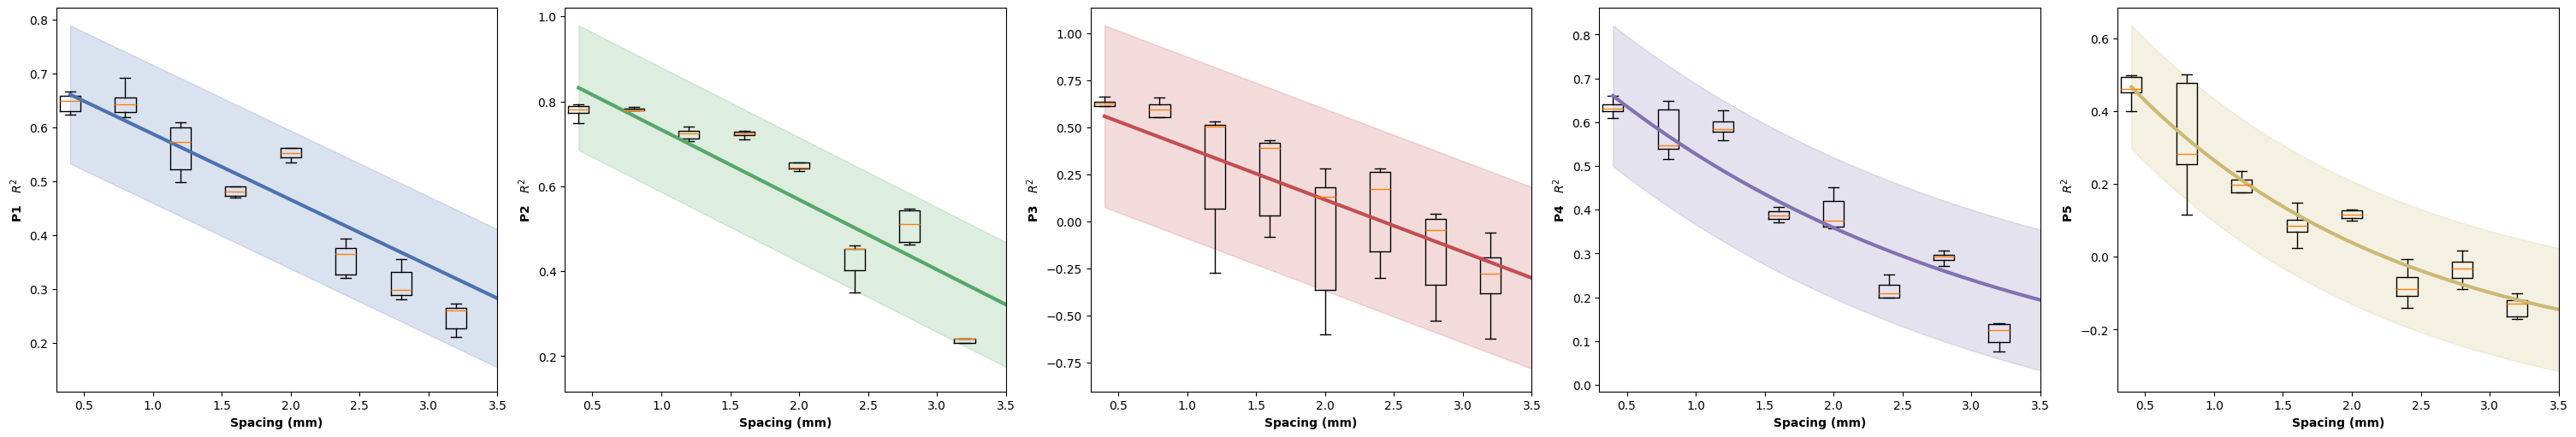

In [7]:
f, ax = plt.subplots(1,5, figsize=(30, 5),constrained_layout=True)
color_set =  ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974']
name_list = ["P1", "P2", "P3","P4", "P5"]
#init = [[1.3626, -0.7586,0],
#        [ 2.01319372, -0.46418438,0],
#        [-0.06920924,0.78730771,0 ],
#        ]
boxes = []
for i in range(5):
    print("-------------------------------")
    name = name_list[i]

    df_sub = df[df["Participant"] == name]
    #ax[i].scatter(df_sub['x'], df_sub['y'], color=color_set[i], alpha=0.2)
    x_pts = df_sub['x'].unique()

    for x_val in x_pts:
        boxes.append(ax[i].boxplot(df_sub[df_sub["x"] == x_val]['y'], positions=[x_val], showfliers=False)) 
        print(boxes[-1]['medians'][0].get_xydata())
        
    # Fit the exponential model
    popt, pcov = curve_fit(exponential_func2,
                            df_sub['x'], 
                            df_sub['y'],
                            #p0=init[name],
                            maxfev=2000)
    
    a_fit, b_fit, c_fit = popt

    # Generate predictions for smooth curve
    x_smooth = np.linspace(df['x'].min(), df['x'].max(), 200)
    y_smooth = exponential_func2(x_smooth, *popt)

    #ax[i].plot(x_smooth, y_smooth, 'r-', linewidth=3, color=color_set[i],label=name_list[i],)
    
    print(f"Fitted parameters:")
    print(f"a = {a_fit:.4f}")
    print(f"b = {b_fit:.4f}")
    print(f"c1 = {c_fit:.4f}")
    print(f"\nEquation: y = {a_fit:.4f} * exp({b_fit:.4f} * x)")
    
    # Calculate R-squared
    y_pred = exponential_func2(df_sub['x'], *popt)
    r = np.corrcoef(y_pred, df_sub['y'].values)[0, 1]
    print(f"R² = {r**2:.4f}")

    #calculate aic
    exp_AIC = aic(df_sub['y'].values, y_pred, k=3)
    print(f"Exp AIC {exp_AIC}")

    # linear model
    slope, intercept = np.polyfit(df_sub['x'].to_numpy(), df_sub['y'].to_numpy(), 1)
    lin_pred = slope * df_sub['x'].to_numpy() + intercept
    aic_lin = aic(df_sub['y'].values, lin_pred, k=2)  # slope + intercept
    print("AIC linear:", aic_lin)
    if (i < 3 ):
        y_smooth = slope*(x_smooth) + intercept

    ax[i].plot(x_smooth, y_smooth, 'r-', linewidth=3, color=color_set[i],label=name_list[i],)
    


    print("Delta",exp_AIC - aic_lin, np.exp( (aic_lin - exp_AIC)/2 ) )
    # Calculate confidence intervals
    # Standard error of the fit
    residuals = df_sub['y'] - lin_pred
    dof = len(df_sub['y']) - len(popt)  # degrees of freedom
    mse = np.sum(residuals**2) / dof
    std_error = np.sqrt(mse)

    # Prediction intervals (95% confidence)
    alpha = 0.05
    t_val = stats.t.ppf(1 - alpha/2, dof)

    # Calculate standard error for each prediction point
    # This is a simplified approach - for more accurate intervals, 
    # you'd need to account for parameter uncertainty
    y_smooth_lower = y_smooth - t_val * std_error
    y_smooth_upper = y_smooth + t_val * std_error

    # Plot confidence intervals
    ax[i].fill_between(x_smooth, y_smooth_lower, y_smooth_upper, 
                 alpha=0.2, color=color_set[i])
    
    ax[i].set_xticks([0.4, 0.8, 1.2, 1.6, 2.0, 2.4, 2.8, 3.2,3.6 ])
    ax[i].set_xticklabels([0.4, 0.8, 1.2, 1.6, 2.0, 2.4, 2.8, 3.2,3.6 ])
    ax[i].set_ylabel(f'{name_list[i]}   ' +r'$R^2$',weight='bold')
    ax[i].set_xscale('linear')
    ax[i].set_xlim([0.3,3.5])
    
    ax[i].grid(False)
    ax[i].set_facecolor('#ffffff')
    ax[i].set_xlabel("Spacing (mm)", weight='bold')
#plt.ylabel(r'%MSE',weight='bold')
#plt.title("Regression Performance Across Electrode Spacing",weight='bold')
#plt.legend()

# Size

In [8]:
#file_16 = "/home/becca/Documents/pn/results/decimate_results_16.csv"
#file_8 = "/home/becca/Documents/pn/decimate_results_8.csv"
#file_full = "/home/becca/Documents/pn/decimate_results_full.csv"
file_list = []
#file_list.append(os.path.join(root_dir, "results", "decimate","density_sweep_wsmoothing.csv" ) )

#file_list.append(os.path.join(root_dir, "results", "decimate","decimate_results_grid_down.csv" ) )
#file_list.append(os.path.join(root_dir, "results", "decimate","density_sweep_moredata.csv" ) )
file_list.append(os.path.join(root_dir, "results", "decimate","fig4b_moredata.csv" ) )
file_list.append(os.path.join(root_dir, "results", "decimate","fig4b_moredata2.csv" ) )
file_list.append(os.path.join(root_dir, "fig4b_moredata3.csv" ) )
#file_list.append(os.path.join(root_dir, "fig4b_moredata4.csv" ) )

#file_list.append(os.path.join(root_dir, "results", "decimate","density1_size10.csv" ) )
#file_list.append(os.path.join(root_dir, "results", "decimate","density1_size16.csv" ) )

#file_list.append(os.path.join(root_dir, "results", "decimate", "s4_densitysweep.csv" ) )
#file_list.append(os.path.join(root_dir, "results", "decimate", "p5_densitysweep.csv" ) )
#file_list.append(os.path.join(root_dir, "results", "decimate", "s5_densitysweep.csv" ) )

df_list = []

for file in file_list:
    new_df = pd.read_csv(file)
    new_df = new_df[new_df['Subject'] != "Subject"]
    new_df['R2'] = new_df['R2'].astype(float)
    #new_df['mse'] = new_df['mse'].astype(float)


    new_df['grid_pos'] = new_df['grid_pos'].astype(float)
    new_df["Spacing"] = .4*(new_df['grid_pos'])


    new_df['x'] = new_df['Count']
    new_df['y'] = new_df['R2'] /2
   # new_df['y'] = new_df['mse']

    df_list.append(new_df)


df = pd.concat(df_list)
conditions = [
    (df['Subject'] == 'NSR-004-002'),
    (df['Subject']=='2'),
    (df['Subject']==2.0),  
    (df['Subject'] == 'NSR-004-003'),
    (df['Subject'] == '3'),
    (df['Subject']==3.0),  

    (df['Subject'] == '4'),
    (df['Subject']==4.0),  

    (df['Subject'] == '5'),
    (df['Subject']==5.0),  

  (df['Subject'] == '102005'),
  (df['Subject']==102005.0),  

      
]
choices = ["P1", "P1","P1", "P2", "P2", "P2", "P3","P3", "P4", "P4","P5", "P5"]
df['Participant'] = np.select(conditions, choices, default='Unknown')
#df = df[ (df['Participant'] != "Unknown") ]

--------------------------------
P1 5.0 4.366963294178914e-05
P1 10.0 7.488885445993505e-05
P1 15.0 0.1171622495151907
P1 20.0 0.8466189525287983
P1 25.0 0.9897218036164265
P1 32.0 0.511545020784039
P1 nan nan
--------------------------------
P2 5.0 0.00016160310277957336
P2 10.0 0.00012632353991290805
P2 15.0 0.0006464124111182935
P2 20.0 0.3104640719115572
P2 25.0 0.5387608328210951
P2 32.0 0.511545020784039
P2 nan nan
--------------------------------
P3 5.0 0.00016160310277957336
P3 10.0 4.366963294178914e-05
P3 15.0 0.00016160310277957336
P3 20.0 0.11126013676237684
P3 25.0 0.2996224179721933
P3 32.0 0.511545020784039
P3 nan nan
--------------------------------
P4 5.0 0.00016160310277957336
P4 10.0 4.366963294178914e-05
P4 15.0 0.07999353587588882
P4 20.0 0.20490569416546817
P4 25.0 0.7466397425610708
P4 32.0 0.511545020784039
P4 nan nan
--------------------------------
P5 5.0 0.00016160310277957336
P5 10.0 4.366963294178914e-05
P5 15.0 0.00016160310277957336
P5 20.0 4.366963294178

C:\Users\Becca\AppData\Roaming\Python\Python312\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\Becca\AppData\Roaming\Python\Python312\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\Becca\AppData\Local\Temp\ipykernel_13540\892815664.py:31: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  stat, p = stats.mannwhitneyu(full_array, subsample, alternative='greater')
C:\Users\Becca\AppData\Roaming\Python\Python312\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\Becca\AppData\Roaming\Python\Python312\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = r

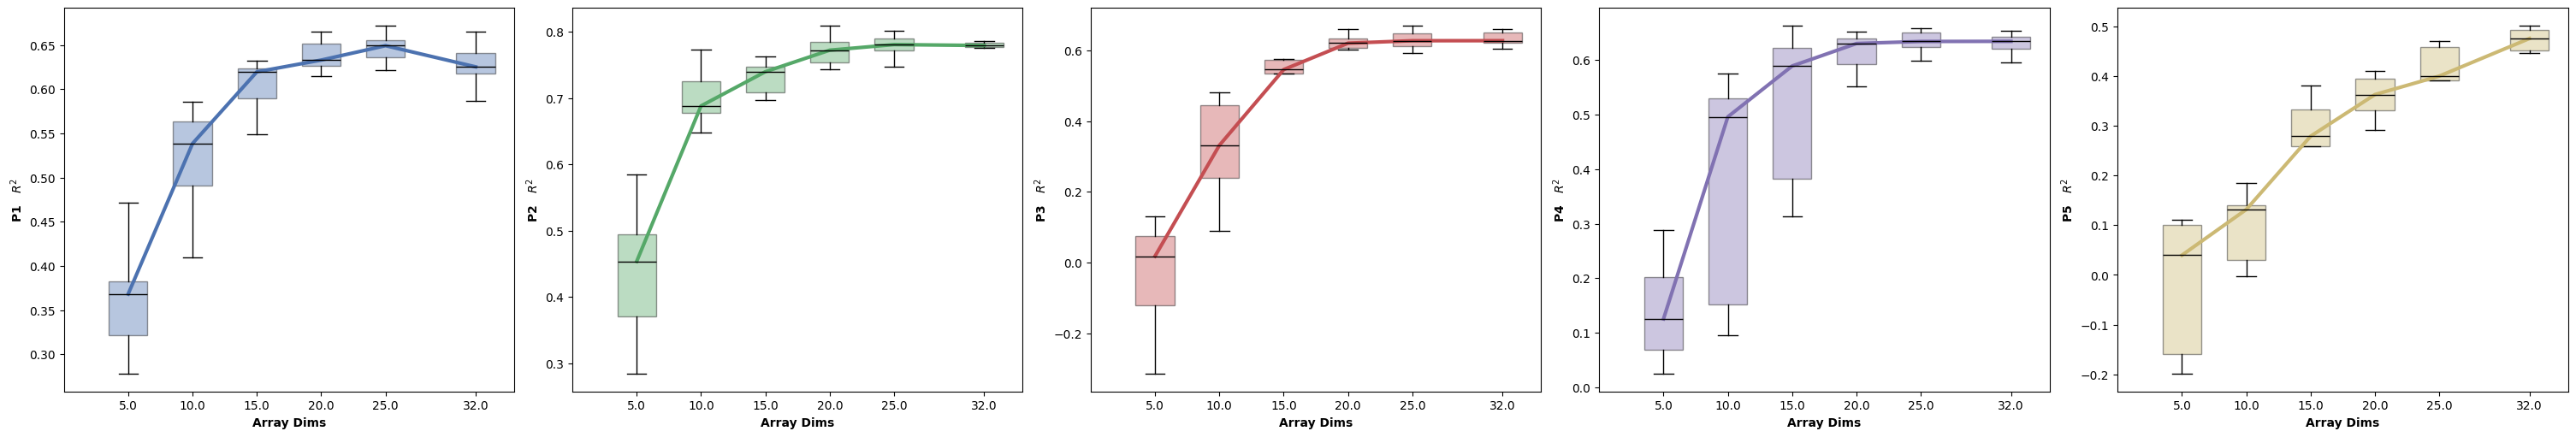

In [9]:
f, ax = plt.subplots(1,5, figsize=(30, 5),constrained_layout=True)

color_set =  ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974']
name_list = ["P1", "P2", "P3","P4", "P5"]
#init = [[1.3626, -0.7586,0],
#        [ 2.01319372, -0.46418438,0],
#        [-0.06920924,0.78730771,0 ],
#        ]

for i in range(5):
    name = name_list[i]

    print("--------------------------------")
    df_sub = df[df["Participant"] == name]
    #ax[i].scatter(df_sub['x'], df_sub['y'], color=color_set[i], alpha=0.2)
    x_pts = np.sort(df_sub['x'].unique() )

    full_array = np.sort(df_sub[df_sub["x"] == 32]['y'].to_numpy())

    med_values = []
    for x_val in x_pts:
        subsample = np.sort(df_sub[df_sub["x"] == x_val]['y'].to_numpy())
        
        box = ax[i].boxplot(subsample, 
                            positions=[x_val], 
                            medianprops=dict(color='black'),
                            showfliers=False, widths=3, patch_artist=True)
        
        med_values.append(np.median(subsample) )

        stat, p = stats.mannwhitneyu(full_array, subsample, alternative='greater')
        print(name, x_val, p)

        for patch in box['boxes']:
            patch.set_facecolor(color_set[i])
            patch.set_alpha(0.4)
    ax[i].plot(x_pts, med_values, color=color_set[i], linewidth=3)        
    ax[i].set_xlim([0,35]) 
    ax[i].set_ylabel(f'{name_list[i]}   ' +r'$R^2$',weight='bold')
    ax[i].set_xlabel(f'Array Dims',weight='bold')


-------------------------------
0, 0, 0.4 Med R2 [[0.325      0.64880472]
 [0.475      0.64880472]]
0, 0, 0.8 Med R2 [[0.725      0.64248379]
 [0.875      0.64248379]]
0, 0, 1.2000000000000002 Med R2 [[1.125      0.57258782]
 [1.275      0.57258782]]
0, 0, 1.6 Med R2 [[1.525      0.48084509]
 [1.675      0.48084509]]
0, 0, 2.0 Med R2 [[1.925      0.55327836]
 [2.075      0.55327836]]
0, 0, 2.4000000000000004 Med R2 [[2.325      0.36455095]
 [2.475      0.36455095]]
0, 0, 2.8000000000000003 Med R2 [[2.725     0.2980465]
 [2.875     0.2980465]]
0, 0, 3.2 Med R2 [[3.125      0.25982055]
 [3.275      0.25982055]]
0, 0, 3.6 Med R2 [[3.525      0.35788468]
 [3.675      0.35788468]]
Fitted parameters:
a = 1.1814
b = 0.1324
c1 = -0.4501

Equation: y = 1.1814 * exp(0.1324 * x)
R² = 0.8224
Exp AIC -300.6611083949125
AIC linear: -301.57744798703663
Delta 0.9163395921241317 0.6324400812547117
-------------------------------
0, 1, 0.4 Med R2 [[0.325      0.78167535]
 [0.475      0.78167535]]
0, 1, 

C:\Users\Becca\AppData\Local\Temp\ipykernel_13540\2911319515.py:130: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  ax[0,i].plot(x_smooth, y_smooth, 'r-', linewidth=3, color=color_set[i],label=name_list[i],)
C:\Users\Becca\AppData\Local\Temp\ipykernel_13540\2911319515.py:130: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  ax[0,i].plot(x_smooth, y_smooth, 'r-', linewidth=3, color=color_set[i],label=name_list[i],)
C:\Users\Becca\AppData\Local\Temp\ipykernel_13540\2911319515.py:130: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  ax[0,i].plot(x_smooth, y_smooth, 'r-', linewidth=3, color=color_set[i],label=name_list[i],)
C:\Users\Becca\AppData\Local\Temp\ipyker

P4, 32.0, [[30.5         0.63406984]
 [33.5         0.63406984]]
P4, nan, [[nan nan]
 [nan nan]]
--------------------------------
P5, 5.0, [[3.5        0.03963217]
 [6.5        0.03963217]]
P5, 10.0, [[ 8.5         0.13151935]
 [11.5         0.13151935]]
P5, 15.0, [[13.5         0.27875903]
 [16.5         0.27875903]]
P5, 20.0, [[18.5         0.36251143]
 [21.5         0.36251143]]
P5, 25.0, [[23.5         0.39961115]
 [26.5         0.39961115]]
P5, 32.0, [[30.5         0.47511072]
 [33.5         0.47511072]]
P5, nan, [[nan nan]
 [nan nan]]


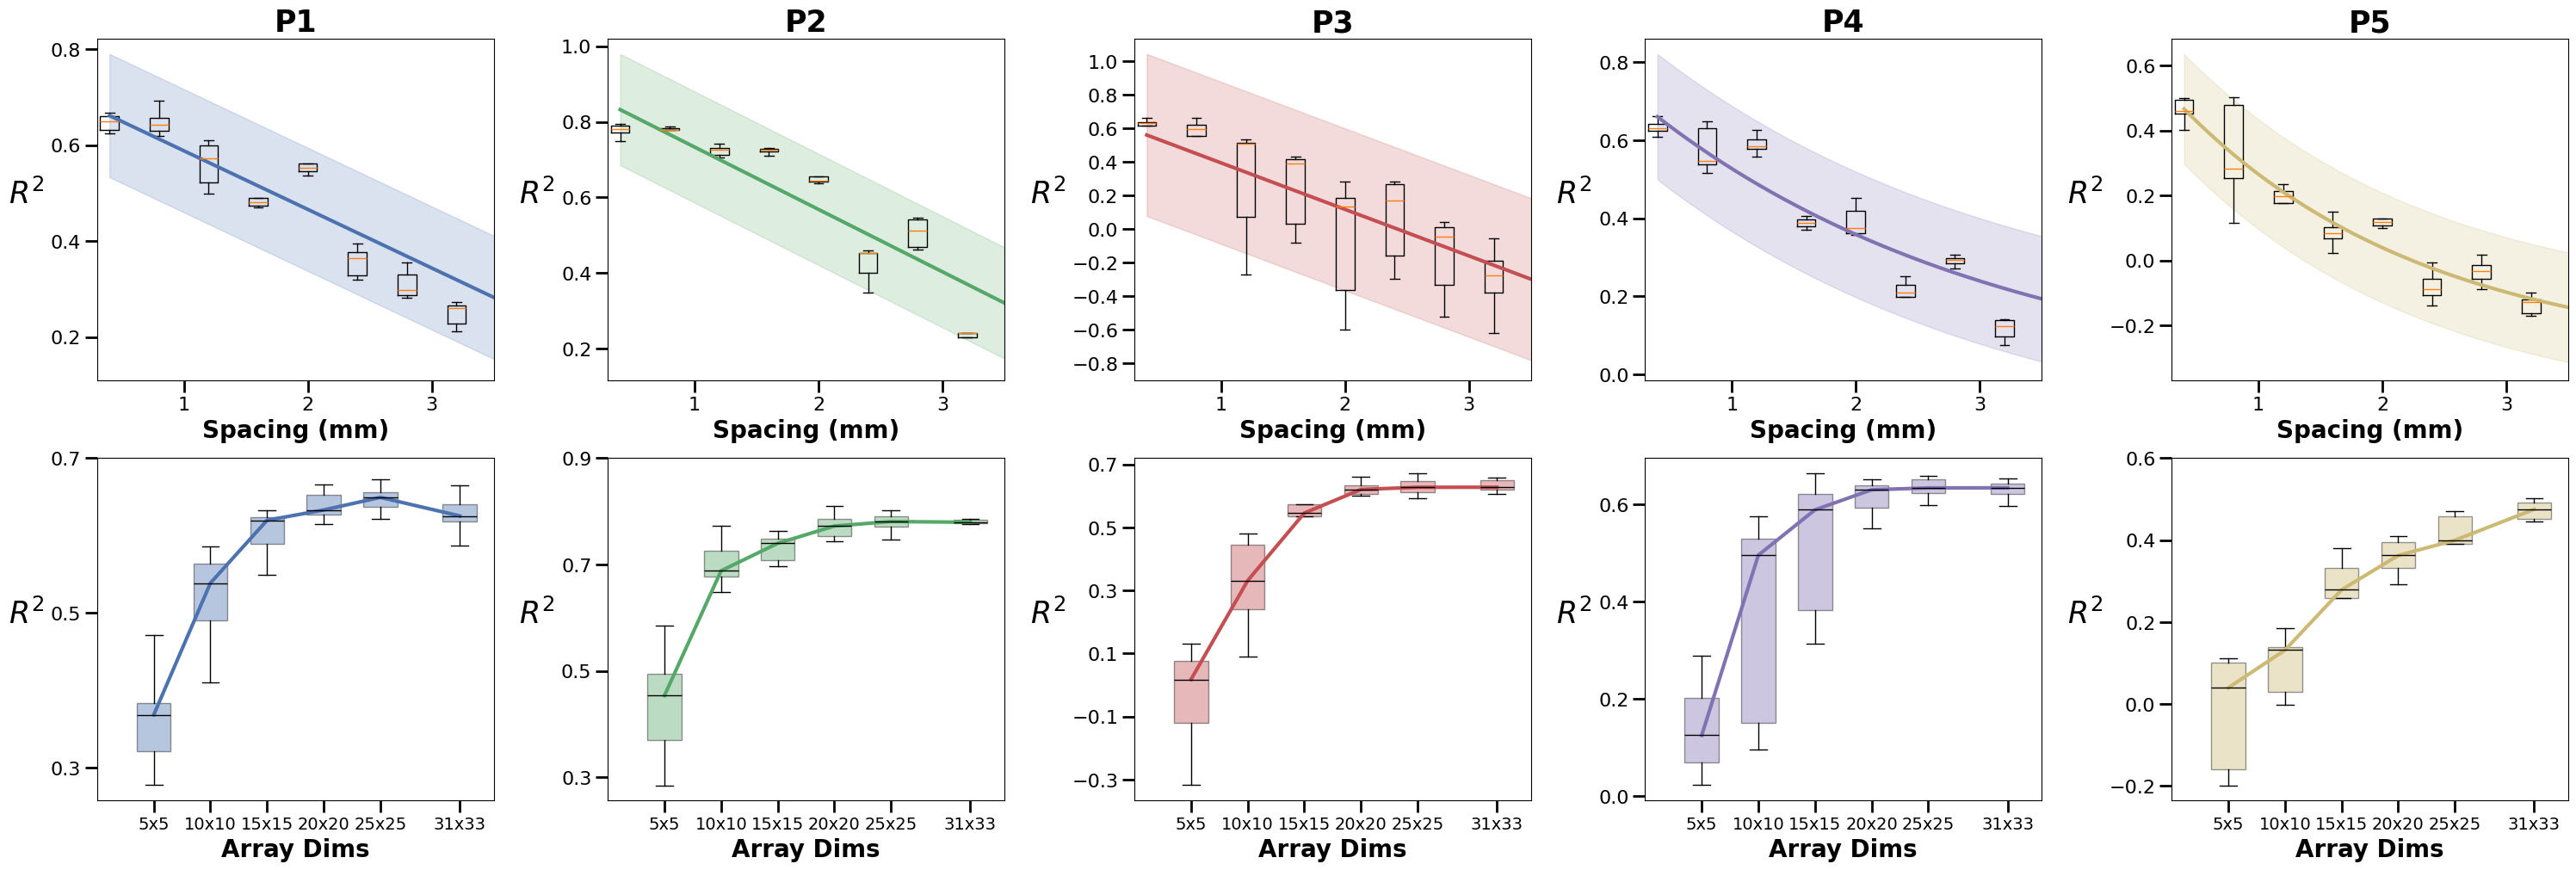

In [28]:
# All together now 

#--------------------------------------------------------------
mpl.rcParams['axes.labelsize'] = 16
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14




#--------------------------------------------------------------
#file_16 = "/home/becca/Documents/pn/results/decimate_results_16.csv"
#file_8 = "/home/becca/Documents/pn/decimate_results_8.csv"
#file_full = "/home/becca/Documents/pn/decimate_results_full.csv"
file_list = []
#file_list.append(os.path.join(root_dir, "results", "decimate","density_sweep_wsmoothing.csv" ) )

#file_list.append(os.path.join(root_dir, "results", "decimate","decimate_results_grid_down.csv" ) )
file_list.append(os.path.join(root_dir, "results", "decimate","density_sweep_moredata.csv" ) )
file_list.append(os.path.join(root_dir, "results", "decimate","fig4b_moredata.csv" ) )
file_list.append(os.path.join(root_dir, "results", "decimate", "s4_densitysweep.csv" ) )
file_list.append(os.path.join(root_dir, "results", "decimate", "p5_densitysweep.csv" ) )
file_list.append(os.path.join(root_dir, "results", "decimate", "s5_densitysweep.csv" ) )

df_list = []

for file in file_list:
    new_df = pd.read_csv(file)
    new_df = new_df[new_df['Subject'] != "Subject"]
    new_df['R2'] = new_df['R2'].astype(float)
    #new_df['mse'] = new_df['mse'].astype(float)


    new_df['grid_pos'] = new_df['grid_pos'].astype(float)
    new_df["Spacing"] = .4*(new_df['grid_pos'])


    new_df['x'] = new_df['Spacing']
    new_df['y'] = new_df['R2'] /2
   # new_df['y'] = new_df['mse']

    df_list.append(new_df)


df = pd.concat(df_list)
conditions = [
    (df['Subject'] == 'NSR-004-002'),
    (df['Subject']=='2'),
    (df['Subject']==2.0),  
    (df['Subject'] == 'NSR-004-003'),
    (df['Subject'] == '3'),
    (df['Subject']==3.0),  

    (df['Subject'] == '4'),
    (df['Subject']==4.0),  

    (df['Subject'] == '5'),
    (df['Subject']==5.0),  

  (df['Subject'] == '102005'),
  (df['Subject']==102005.0),  

      
]
choices = ["P1", "P1","P1", "P2", "P2", "P2", "P3","P3", "P4", "P4","P5", "P5"]
df['Participant'] = np.select(conditions, choices, default='Unknown')
#df = df[ (df['Participant'] != "Unknown") ]




f, ax = plt.subplots(2,5, figsize=(30, 10),constrained_layout=True)
color_set =  ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974']
name_list = ["P1", "P2", "P3","P4", "P5"]
#init = [[1.3626, -0.7586,0],
#        [ 2.01319372, -0.46418438,0],
#        [-0.06920924,0.78730771,0 ],
#        ]

boxes = []
for i in range(5):
    print("-------------------------------")
    name = name_list[i]

    df_sub = df[df["Participant"] == name]
    #ax[i].scatter(df_sub['x'], df_sub['y'], color=color_set[i], alpha=0.2)
    x_pts = df_sub['x'].unique()

    for x_val in x_pts:
        boxes.append(ax[0,i].boxplot(df_sub[df_sub["x"] == x_val]['y'], positions=[x_val], showfliers=False) )
        print(f'0, {i}, {x_val} Med R2 {boxes[-1]['medians'][0].get_xydata()}')
    # Fit the exponential model
    popt, pcov = curve_fit(exponential_func2,
                            df_sub['x'], 
                            df_sub['y'],
                            #p0=init[name],
                            maxfev=2000)
    
    a_fit, b_fit, c_fit = popt

    # Generate predictions for smooth curve
    x_smooth = np.linspace(df['x'].min(), df['x'].max(), 200)
    y_smooth = exponential_func2(x_smooth, *popt)

    #ax[i].plot(x_smooth, y_smooth, 'r-', linewidth=3, color=color_set[i],label=name_list[i],)
    
    print(f"Fitted parameters:")
    print(f"a = {a_fit:.4f}")
    print(f"b = {b_fit:.4f}")
    print(f"c1 = {c_fit:.4f}")
    print(f"\nEquation: y = {a_fit:.4f} * exp({b_fit:.4f} * x)")
    
    # Calculate R-squared
    y_pred = exponential_func2(df_sub['x'], *popt)
    r = np.corrcoef(y_pred, df_sub['y'].values)[0, 1]
    print(f"R² = {r**2:.4f}")

    #calculate aic
    exp_AIC = aic(df_sub['y'].values, y_pred, k=3)
    print(f"Exp AIC {exp_AIC}")

    # linear model
    slope, intercept = np.polyfit(df_sub['x'].to_numpy(), df_sub['y'].to_numpy(), 1)
    lin_pred = slope * df_sub['x'].to_numpy() + intercept
    aic_lin = aic(df_sub['y'].values, lin_pred, k=2)  # slope + intercept
    print("AIC linear:", aic_lin)
    if (i < 3 ):
        y_smooth = slope*(x_smooth) + intercept

    ax[0,i].plot(x_smooth, y_smooth, 'r-', linewidth=3, color=color_set[i],label=name_list[i],)
    


    print("Delta",exp_AIC - aic_lin, np.exp( (aic_lin - exp_AIC)/2 ) )
    # Calculate confidence intervals
    # Standard error of the fit
    residuals = df_sub['y'] - lin_pred
    dof = len(df_sub['y']) - len(popt)  # degrees of freedom
    mse = np.sum(residuals**2) / dof
    std_error = np.sqrt(mse)

    # Prediction intervals (95% confidence)
    alpha = 0.05
    t_val = stats.t.ppf(1 - alpha/2, dof)

    # Calculate standard error for each prediction point
    # This is a simplified approach - for more accurate intervals, 
    # you'd need to account for parameter uncertainty
    y_smooth_lower = y_smooth - t_val * std_error
    y_smooth_upper = y_smooth + t_val * std_error

    # Plot confidence intervals
    ax[0,i].fill_between(x_smooth, y_smooth_lower, y_smooth_upper, 
                 alpha=0.2, color=color_set[i])
    
    ax[0,i].set_xticks([0.4, 0.8, 1.2, 1.6, 2.0, 2.4, 2.8, 3.2,3.6 ])
    ax[0,i].set_xticklabels([0.4, 0.8, 1.2, 1.6, 2.0, 2.4, 2.8, 3.2,3.6 ])
    ax[0,i].set_ylabel(r'$R^2$',weight='bold', size=25,rotation=0,labelpad=20)
    ax[0,i].set_xscale('linear')
    ax[0,i].set_xlim([0.3,3.5])
    #ax[0,i].set_ylim([0,1])
    #ax[0,i].set_yticks([0,1])
    ax[0,i].grid(False)
    ax[0,i].set_facecolor('#ffffff')
    ax[0,i].set_xlabel("Spacing (mm)", weight='bold', size=20)
    ax[0,i].set_title(f'{name}', weight='bold', size=25)

    ymin, ymax = ax[0,i].get_ylim()
    
    step = 0.2

    ymin = np.ceil(ymin / step) * step
    ymax = np.floor(ymax / step) * step

    ax[0,i].yaxis.set_major_locator(FixedLocator([ymin, ymax]))
    ax[0,i].set_yticks(np.arange(ymin, ymax+0.1, step))
    ax[0,i].tick_params(axis='both',
                        reset=True,
                        labelsize=16,
                        length=10,
                        width=2,
                        colors='k',
                        right=False,
                        top=False)

#plt.ylabel(r'%MSE',weight='bold')
#plt.title("Regression Performance Across Electrode Spacing",weight='bold')
#plt.legend()




#------------------------------------------------------------
#file_16 = "/home/becca/Documents/pn/results/decimate_results_16.csv"
#file_8 = "/home/becca/Documents/pn/decimate_results_8.csv"
#file_full = "/home/becca/Documents/pn/decimate_results_full.csv"
file_list = []
#file_list.append(os.path.join(root_dir, "results", "decimate","density_sweep_wsmoothing.csv" ) )

#file_list.append(os.path.join(root_dir, "results", "decimate","decimate_results_grid_down.csv" ) )
#file_list.append(os.path.join(root_dir, "results", "decimate","density_sweep_moredata.csv" ) )
file_list.append(os.path.join(root_dir, "results", "decimate","fig4b_moredata.csv" ) )
file_list.append(os.path.join(root_dir, "results", "decimate","fig4b_moredata2.csv" ) )
file_list.append(os.path.join(root_dir, "fig4b_moredata3.csv" ) )
#file_list.append(os.path.join(root_dir, "fig4b_moredata4.csv" ) )

#file_list.append(os.path.join(root_dir, "results", "decimate","density1_size10.csv" ) )
#file_list.append(os.path.join(root_dir, "results", "decimate","density1_size16.csv" ) )

#file_list.append(os.path.join(root_dir, "results", "decimate", "s4_densitysweep.csv" ) )
#file_list.append(os.path.join(root_dir, "results", "decimate", "p5_densitysweep.csv" ) )
#file_list.append(os.path.join(root_dir, "results", "decimate", "s5_densitysweep.csv" ) )

df_list = []

for file in file_list:
    new_df = pd.read_csv(file)
    new_df = new_df[new_df['Subject'] != "Subject"]
    new_df['R2'] = new_df['R2'].astype(float)
    #new_df['mse'] = new_df['mse'].astype(float)


    new_df['grid_pos'] = new_df['grid_pos'].astype(float)
    new_df["Spacing"] = .4*(new_df['grid_pos'])


    new_df['x'] = new_df['Count']
    new_df['y'] = new_df['R2'] /2
   # new_df['y'] = new_df['mse']

    df_list.append(new_df)


df = pd.concat(df_list)
conditions = [
    (df['Subject'] == 'NSR-004-002'),
    (df['Subject']=='2'),
    (df['Subject']==2.0),  
    (df['Subject'] == 'NSR-004-003'),
    (df['Subject'] == '3'),
    (df['Subject']==3.0),  

    (df['Subject'] == '4'),
    (df['Subject']==4.0),  

    (df['Subject'] == '5'),
    (df['Subject']==5.0),  

  (df['Subject'] == '102005'),
  (df['Subject']==102005.0),  

      
]
choices = ["P1", "P1","P1", "P2", "P2", "P2", "P3","P3", "P4", "P4","P5", "P5"]
df['Participant'] = np.select(conditions, choices, default='Unknown')
#df = df[ (df['Participant'] != "Unknown") ]


for i in range(5):
    name = name_list[i]

    print("--------------------------------")
    df_sub = df[df["Participant"] == name]
    #ax[i].scatter(df_sub['x'], df_sub['y'], color=color_set[i], alpha=0.2)
    x_pts = np.sort(df_sub['x'].unique() )

    full_array = np.sort(df_sub[df_sub["x"] == 32]['y'].to_numpy())

    med_values = []
    for x_val in x_pts:
        subsample = np.sort(df_sub[df_sub["x"] == x_val]['y'].to_numpy())
        
        box = ax[1,i].boxplot(subsample, 
                            positions=[x_val], 
                            medianprops=dict(color='black'),
                            showfliers=False, widths=3, patch_artist=True)
        
        print(f'{name}, {x_val}, {box['medians'][0].get_xydata()}')
        med_values.append(np.median(subsample) )

        #stat, p = stats.mannwhitneyu(full_array, subsample, alternative='greater')
        #print(name, x_val, p)

        for patch in box['boxes']:
            patch.set_facecolor(color_set[i])
            patch.set_alpha(0.4)
    ax[1,i].plot(x_pts, med_values, color=color_set[i], linewidth=3)        
    ax[1,i].set_xlim([0,35]) 
    ax[1,i].set_xticks([5,10, 15,20,25, 32]) 
    ax[1,i].set_xticklabels(['5x5','10x10','15x15', '20x20', '25x25', '31x33']) 

    #ax[1,i].set_ylim([0,1])
    ax[1,i].set_ylabel(r'$R^2$',weight='bold', size=25,rotation=0, labelpad=20)
    ax[1,i].set_xlabel(f'Array Dims',weight='bold',size=20)
    ax[1,i].locator_params(axis='y', nbins=2)

    ax[1,i].tick_params(axis='y',
                        reset=True,
                        labelsize=16,
                        length=10,
                        width=2,
                        colors='k',
                        right=False,
                        top=False)
    ax[1,i].tick_params(axis='x',
                            reset=True,
                            labelsize=14,
                            length=10,
                            width=2,
                            colors='k',
                            right=False,
                            top=False)
    ymin, ymax = ax[1,i].get_ylim()

    step = 0.1

    ymin = np.ceil(ymin / step) * step
    ymax = np.floor(ymax / step) * step
    
    #ax[1,i].set_xticks([0,31]) 

    ax[1,i].yaxis.set_major_locator(FixedLocator([ymin, ymax]))
    ax[1,i].set_yticks(np.arange(ymin, ymax+0.15, 0.2))



# OLD

In [ ]:
probe_map_path =  '../config/Precision_map_v2.xml'
map = pos_to_electrode_map(probe_map_path)

set_list = get_electrode_subsets(map, [25], 1) 
#set_list = get_electrode_subsets_density(map, 9)
if(len(set_list) > 3):
    set_idxs = np.linspace(0,len(set_list)-1, 3).astype(int)
    print(set_idxs)
    set_list = [set_list[i] for i in set_idxs]

In [ ]:
sns.set_theme(style="darkgrid")
ax = sns.lmplot(x="Spacing", y="R2",  hue="Participant", data=df,
                y_jitter=.005, logistic=True,  truncate=False)

plt.xlabel("Spacing (mm)", weight='bold')
plt.ylabel('% MSE ',weight='bold')
plt.title("Regression Performance Across Electrode Spacing",weight='bold')

In [ ]:
sns.set_theme(style="whitegrid")

# "Melt" the dataset to "long-form" or "tidy" representation
#iris = iris.melt(id_vars="species", var_name="measurement")

# Initialize the figure
f, ax = plt.subplots()
sns.despine(bottom=True, left=True)


#ax.set_xticks([-1, -0.5, 0, 0.5, 1, 1.5, 2])


# Show each observation with a scatterplot
sns.stripplot(
    data=df_all, x="R2", y="Subject", hue="gridsize",
    dodge=True, alpha=.25, zorder=1, legend=True,
)

plt.title("Coefficient of Determination")
# Show the conditional means, aligning each pointplot in the
# center of the strips by adjusting the width allotted to each
# category (.8 by default) by the number of hue levels
#sns.pointplot(
#    data=iris, x="value", y="measurement", hue="species",
#    dodge=.8 - .8 / 3, palette="dark", errorbar=None,
#    markers="d", markersize=4, linestyle="none",
#)

# Improve the legend
#sns.move_legend(
#    ax, loc="lower right", ncol=3, frameon=True, columnspacing=1, handletextpad=0,
#)


In [ ]:
probe_map_path =  '../config/Precision_map_v2.xml'
DATA_ROOT = '/home/becca/Data/PN_preprocessed/' 
map = pos_to_electrode_map(probe_map_path)
set_list_16 = get_electrode_subsets(map, [16], density=1)

subject = "NSR-004-002"

df_16_subject =  df_16[df_16['Subject'] == subject]



In [ ]:
probe_map_path =  '../config/Precision_map_v2.xml'
DATA_ROOT = '/home/becca/Data/PN_preprocessed/' 
map = pos_to_electrode_map(probe_map_path)
set_list_16 = get_electrode_subsets(map, [16], density=1)

subject = "NSR-004-002"

for subject in ["NSR-004-002", "NSR-004-003","NSR-004-004"]:
    df_16_subject =  df_16[df_16['Subject'] == subject]
    
    
    #calculate mean r2
    map_sum = np.zeros([1024])
    map_count = np.zeros([1024])
    
    for row_num in range(len(df_16_subject)):
        data_point = df_16_subject.iloc[row_num]
        point_set = set_list_16[data_point['grid_pos']]
        for electrode in point_set:
            map_sum[int(electrode)] += data_point['R2'] / 2
            map_count[int(electrode)] += 1
    
    ## Plot results 
    map_shape = np.shape(map)
    result_grid = np.zeros(map_shape)
    for x in range(map_shape[0]):
        for y in range(map_shape[1]):
            electrode = int(map[x,y]) 
            count = map_count[electrode]
            if (count >0):
                result_grid[x,y] = map_sum[electrode] / count
    
    plt.figure()
    plt.pcolor(result_grid, vmin=0, vmax=0.5)
    cbar = plt.colorbar()
    cbar.set_label("Mean R2")
    plt.title(subject)


In [ ]:
probe_map_path =  '../config/Precision_map_v2.xml'
DATA_ROOT = '/home/becca/Data/PN_preprocessed/' 
map = pos_to_electrode_map(probe_map_path)
set_list_8 = get_electrode_subsets(map, [8], density=1)

subject = "NSR-004-002"

for subject in ["NSR-004-002", "NSR-004-003","NSR-004-004"]:
    df_8_subject =  df_8[df_8['Subject'] == subject]
    
    
    #calculate mean r2
    map_sum = np.zeros([1024])
    map_count = np.zeros([1024])
    
    for row_num in range(len(df_8_subject)):
        data_point = df_8_subject.iloc[row_num]
        point_set = set_list_8[int(data_point['grid_pos'])]
        for electrode in point_set:
            map_sum[int(electrode)] += data_point['R2'] /2
            map_count[int(electrode)] += 1
    
    ## Plot results 
    map_shape = np.shape(map)
    result_grid = np.zeros(map_shape)
    for x in range(map_shape[0]):
        for y in range(map_shape[1]):
            electrode = int(map[x,y]) 
            count = map_count[electrode]
            if (count >0):
                result_grid[x,y] = map_sum[electrode] / count
    
    plt.figure()
    plt.pcolor(result_grid, vmin=0, vmax=0.5)
    cbar = plt.colorbar()
    cbar.set_label("Mean R2")
    plt.title(subject)

In [ ]:
for i in range(16,32):
    print(i, len(get_electrode_subsets(map, [i], density=1) )  )